# Dataset Statistics: Identification Counts & Coefficients of Variation

Characterises three fundamental quality dimensions of the SCI proteomics dataset across all participating laboratories:

1. **Identification counts** — how many precursors and proteins are detected per single cell, broken down by lab and biological condition.
2. **Coefficients of variation (CVs)** — within-condition reproducibility of quantification, measured as `CV = (std / mean) × 100` per feature.
3. **Missingness heatmap** — binary identification landscape across the full feature space, revealing the sparsity structure and condition-specific detection patterns per lab.

These metrics establish the analytical quality baseline for the dataset and are used in **Figure 3** of the manuscript.

**Inputs** (`Data/AnnData/`)

| File | Description |
|---|---|
| `adata_precursor.h5ad` | Precursor-level quantification (samples × precursors) |
| `adata_protein.h5ad` | Protein-level quantification (samples × protein groups) |

**Outputs** (`Figures/Figure_3/`)

All figures are saved as png, svg, and pdf.

| Panel | File | Description |
|---|---|---|
| A | `count_boxplots/counts_overview_precursors` | Precursor ID counts, all labs combined |
| A | `count_boxplots/counts_overview_precursors_SPLIT` | Precursor ID counts, one panel per lab |
| A | `count_boxplots/counts_overview_proteins` | Protein ID counts, all labs combined |
| A | `count_boxplots/counts_overview_proteins_SPLIT` | Protein ID counts, one panel per lab |
| A | `count_boxplots/pct_contaminants_<feature>`| Percentage of total identifications coming from contaminants |
| B | `CV/CV_overview_proteins_common_box` | Protein CVs, common proteome |
| B | `CV/CV_overview_proteins_all_box` | Protein CVs, per-condition proteome |
| B | `CV/CV_overview_precursors_common_box` | Precursor CVs, common proteome |
| B | `CV/CV_overview_precursors_all_box` | Precursor CVs, per-condition proteome |
| C | `ID_Heatmap/{lab}_identification_heatmap` | Per-lab binary missingness heatmap (precursor & protein) |
| C | `ID_Heatmap/legend_heatmap_conditions` | Condition colour legend |
| C | `ID_Heatmap/legend_heatmap_identification` | Identification/missing colour legend |

---

## Imports

In [1]:
import os
from tqdm import tqdm
import numpy as np
from pathlib import Path
import anndata

from SCI_py.plot.identifications import plot_counts_overview
from SCI_py.metrics.cvs import compute_cv_matrix
from SCI_py.plot.cvs import plot_cvs_overview
from SCI_py.plot.identifications import plot_identification_heatmap

tqdm.pandas()

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables, which is useful for running the notebook on a different machine, with user-defined storage locations, without editing the notebook.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

AnnData objects are expected under `ROOT_OUT/AnnData/`, produced by `02_Results_to_AnnData.ipynb`.

In [4]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

# FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/DIANN/second_pass"
FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/Spectronaut"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

# Change if paths don't match.
# Or change the path after AnnData to specify search result of given search tool.
# ADATA_PRECURSOR_PATH = os.path.join(ROOT_OUT, 'AnnData', 'DIANN', 'second_pass', 'base', 'adata_precursor.h5ad')
# ADATA_PROTEIN_PATH =  os.path.join(ROOT_OUT, 'AnnData', 'DIANN', 'second_pass', 'base', 'adata_protein.h5ad')

ADATA_PRECURSOR_PATH = os.path.join(ROOT_OUT, 'AnnData', 'Spectronaut', 'base', 'adata_precursor.h5ad')
ADATA_PROTEIN_PATH =  os.path.join(ROOT_OUT, 'AnnData', 'Spectronaut', 'base', 'adata_protein.h5ad')

if not os.path.exists(ADATA_PRECURSOR_PATH):
    print(f'Warning: File not found at {ADATA_PRECURSOR_PATH}. Specify the correct path to the AnnData object.')
if not os.path.exists(ADATA_PROTEIN_PATH):
    print(f'Warning: File not found at {ADATA_PROTEIN_PATH}. Specify the correct path to the AnnData object.')

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures/Spectronaut


In [5]:
SHOW_FIGURES = False

## 1. Load Data

Load the pre-processed AnnData objects for **precursor-level** and **protein-level** quantification. Both contain 3,114 samples (observations) with shared `obs` metadata (morphological measurements, experimental annotations, QC flags) but different feature spaces — 72,061 precursors and 7231 protein groups at the time of writing. Raw intensities are in `adata.X`; log₂-transformed intensities are in `adata.layers['X_log2']`.

In [6]:
adata_precursor = anndata.io.read_h5ad(ADATA_PRECURSOR_PATH)
adata_protein = anndata.io.read_h5ad(ADATA_PROTEIN_PATH)

In [5]:
adata_precursor

AnnData object with n_obs × n_vars = 2587 × 56328
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes', 'Stripped.Sequence', 'Proteotypic', 'Modified.Sequence', 'Precursor.Charge', 'Precursor.Id', 'Precursor.Mz', 'Decoy', 'Q.Value', 'Global.Q.Value', 'Lib.Q.Value', 'PEP', 'Peptidoform.Q.Value', 'Global.Peptidoform.Q.Value', 'PG.Q.Value', 'PG.PEP', 'Global.PG.Q.Value', 'Protein.Q.Value', 'GG.Q.Value', 'Channe

In [6]:
adata_protein

AnnData object with n_obs × n_vars = 2587 × 6321
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'Protein.Ids', 'Protein.Names', 'Genes', 'Contaminant'
    layers: 'Global.PG.Q.Value', 'PG.MaxLFQ.Quality', 'PG.PEP', 'PG.Q.Value', 'PG.TopN', 'Protein.Q.Value', 'X_log2'

In [28]:
def plot_counts_overview(
    adata,
    count_col:        str,
    adata2:           'AnnData | None' = None,
    dataset_labels:   tuple[str, str]  = ('Dataset 1', 'Dataset 2'),
    dataset_palette:  dict | list      = None,
    conditions:       list[str]        = CONDITION_ORDER,
    split_conditions: bool             = False,
    show_xlabels:     bool             = False,
    save_dir:         str | None       = None,
    filename:         str              = 'counts_overview.png',
    title:            str | None       = None,
    show:             bool             = True,
):
    """
    Plot per-cell identification counts grouped by lab.

    If ``adata2`` is provided, each lab on the x-axis shows a pair of
    boxes (one per dataset) side by side.
    """
    ylabel          = _metric_label(count_col)
    condition_order = [c for c in CONDITION_ORDER if c in conditions]

    def _prep(a, label):
        df            = a.obs[a.obs['source name'].isin(conditions)].copy()
        df['dataset'] = label
        return df

    if adata2 is None:
        data         = _prep(adata, dataset_labels[0])
        compare_mode = False
    else:
        data = pd.concat(
            [_prep(adata, dataset_labels[0]), _prep(adata2, dataset_labels[1])],
            ignore_index=True,
        )
        compare_mode = True

    # Default palette for the two-dataset comparison.
    if dataset_palette is None:
        dataset_palette = {
            dataset_labels[0]: '#007548',
            dataset_labels[1]: '#d42f2f',
        }

    # Boxplot kwargs differ between modes because hue changes.
    if compare_mode:
        _boxplot_kwargs = dict(
            hue        = 'dataset',
            hue_order  = list(dataset_labels),
            palette    = dataset_palette,
            width      = 0.6,
            flierprops = dict(marker='o', markersize=2, alpha=0.4),
        )
    else:
        _boxplot_kwargs = dict(
            hue        = 'plate_idx',
            hue_order  = LAB_ORDER,
            palette    = LAB_COLORS,
            width      = 0.6,
            flierprops = dict(marker='o', markersize=2, alpha=0.4),
        )

    if split_conditions:
        n         = len(condition_order)
        fig, axes = plt.subplots(1, n, figsize=(4 * n, 5), sharey=False)
        axes      = [axes] if n == 1 else list(axes)

        for ax, condition in zip(axes, condition_order):
            sub = data[data['source name'] == condition]

            sns.boxplot(
                data  = sub,
                x     = 'plate_idx',
                y     = count_col,
                order = LAB_ORDER,
                ax    = ax,
                **_boxplot_kwargs,
            )

            if show_xlabels:
                ax.set(title=condition,
                       xlabel='Lab',
                       ylabel=ylabel if ax == axes[0] else '')
                ax.tick_params(axis='x', rotation=90)
            else:
                ax.set(title=condition,
                       xlabel='',
                       ylabel=ylabel if ax == axes[0] else '')
                ax.set_xticklabels([])

            # Keep legend only on the last axis to avoid duplicates.
            if ax is not axes[-1] and ax.get_legend() is not None:
                ax.get_legend().remove()

        fig.suptitle(title or f'{ylabel} per lab', fontweight='bold')

    else:
        fig, ax = plt.subplots(figsize=(max(14, 2 * len(condition_order)), 6))
        sns.boxplot(
            data  = data,
            x     = 'source name',
            y     = count_col,
            order = condition_order,
            ax    = ax,
            **_boxplot_kwargs,
        )
        ax.set(
            xlabel = 'Condition',
            ylabel = ylabel,
            title  = title or f'{ylabel} per condition',
        )
        ax.tick_params(axis='x', rotation=90)
        if not compare_mode and ax.get_legend() is not None:
            ax.get_legend().remove()
        axes = [ax]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, filename))
        if compare_mode:
            _save_legend_from_mapping(dataset_palette, save_dir, title='Dataset')
        else:
            _save_legend_from_mapping(LAB_COLORS, save_dir, title='Lab')

    if show:
        plt.show()
    else:
        plt.close(fig)

In [23]:
adata_precursor_diann = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/DIANN/second_pass/out/adata_precursor.h5ad')
adata_precursor_spectronaut = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/Spectronaut/out/adata_precursor.h5ad')

In [24]:
adata_protein_diann = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/DIANN/second_pass/out/adata_protein.h5ad')
adata_protein_spectronaut = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/Spectronaut/out/adata_protein.h5ad')

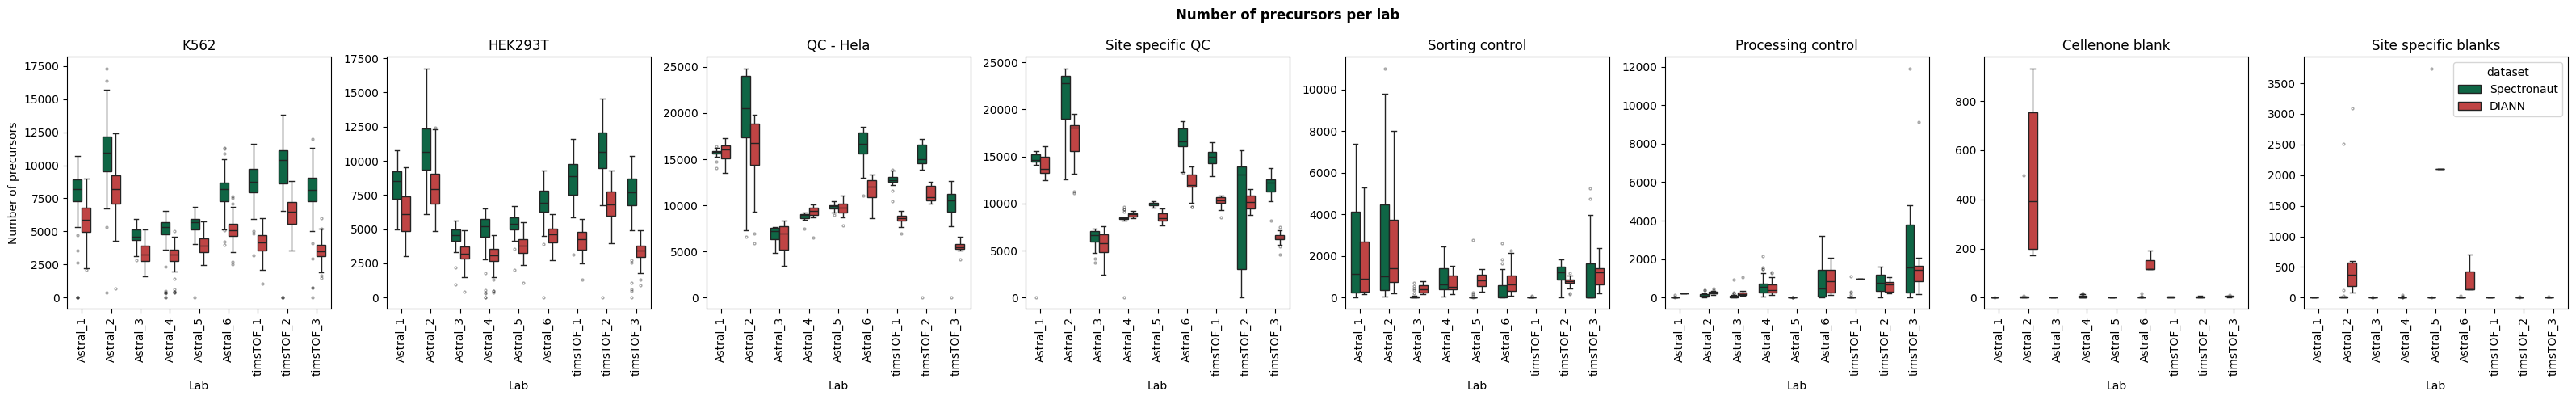

In [29]:
plot_counts_overview(
    adata=adata_precursor_spectronaut,
    adata2=adata_precursor_diann,
    dataset_labels=('Spectronaut', 'DIANN'),
    count_col='n_precursors',
    split_conditions=True,
    show_xlabels=True,
    # save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors_SPLIT_compare.png',
    show=True,
)

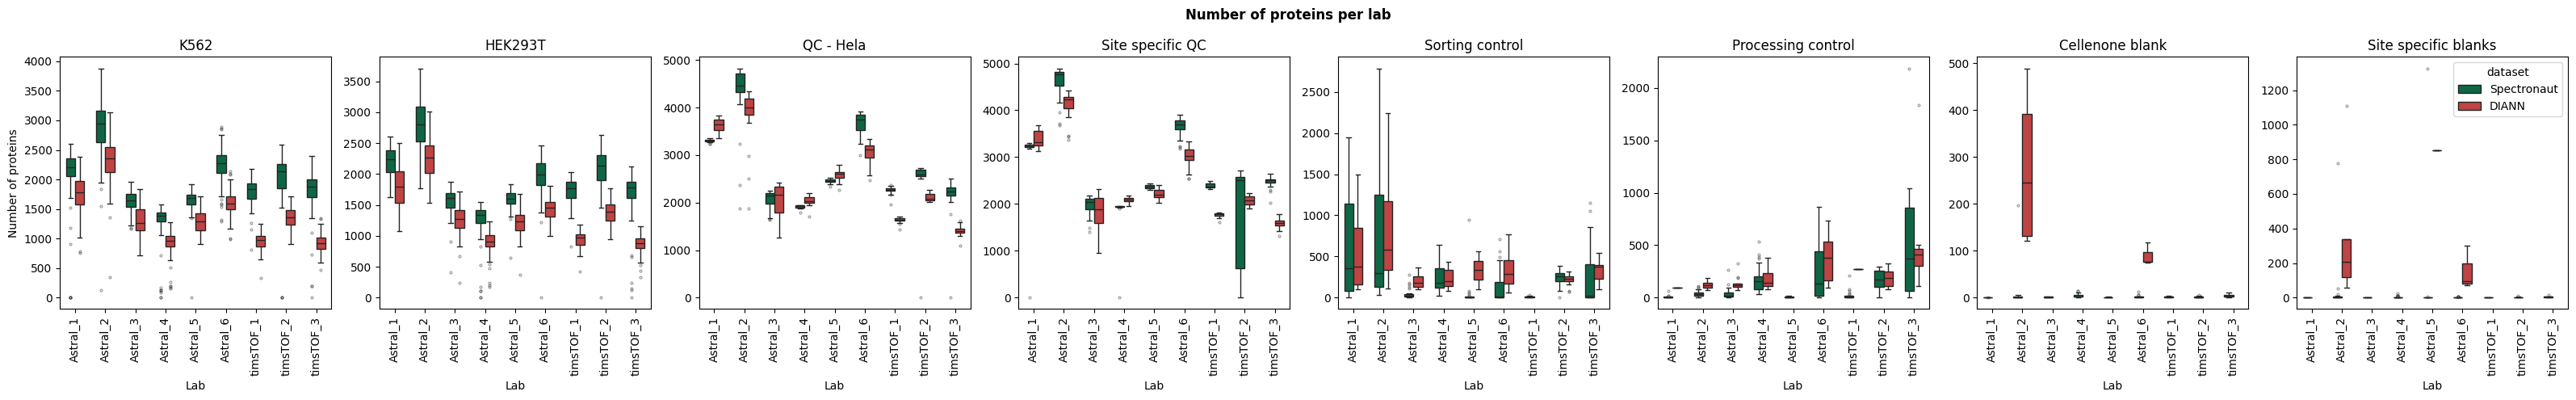

In [30]:
plot_counts_overview(
    adata=adata_protein_spectronaut,
    adata2=adata_protein_diann,
    dataset_labels=('Spectronaut', 'DIANN'),
    count_col='n_proteins',
    split_conditions=True,
    show_xlabels=True,
    # save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors_SPLIT_compare.png',
    show=True,
)

## 2. Identifications

The number of identified precursors/proteins per sample is computed as the count of non-missing (`non-NaN`) entries in `adata.X` and stored in `adata.obs` as `n_precursors` and `n_proteins` respectively. This reflects the number of features quantified in a given single cell after Spectronaut's search.

Box plots are generated for each quantification level in two layouts:

- **Combined** (`split_conditions=False`) — all labs in a single panel, coloured by condition. Gives an overall picture of identification depth across the dataset.
- **Split** (`split_conditions=True`, `show_xlabels=False`) — one panel per lab. Reveals inter-site variability and instrument-platform differences (Astral vs. timsTOF) that are less clear in the combined view.

All figures are saved to `Figures/Figure_3/` without displaying inline (`show=False`) to keep the notebook output lightweight. If you want to see the figures inline, set the SHOW_FIGURES variable (defined above in the notebook) to True.

In [7]:
adata_precursor.obs['n_precursors_withCont'] = np.sum(~np.isnan(adata_precursor.X), axis=1)
adata_protein.obs['n_proteins_withCont'] = np.sum(~np.isnan(adata_protein.X), axis=1)

adata_precursor.obs['n_precursors'] = np.sum(~np.isnan(
    adata_precursor[:, ~adata_precursor.var['Contaminant']].X
), axis=1)
adata_protein.obs['n_proteins'] = np.sum(~np.isnan(
    adata_protein[:, ~adata_protein.var['Contaminant']].X
), axis=1)

# Compute contaminant percentage per cell
adata_protein.obs['pct_contaminant'] = (
    (adata_protein.obs['n_proteins_withCont'] - adata_protein.obs['n_proteins'])
    / adata_protein.obs['n_proteins_withCont'] * 100
)

adata_precursor.obs['pct_contaminant'] = (
    (adata_precursor.obs['n_precursors_withCont'] - adata_precursor.obs['n_precursors'])
    / adata_precursor.obs['n_precursors_withCont'] * 100
)

In [8]:
# Precursor boxplots for identifications, splitted view, and shown in one figure
plot_counts_overview(
    adata=adata_precursor,
    count_col='n_precursors',
    split_conditions=True,
    show_xlabels=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors_SPLIT.png',
    show=SHOW_FIGURES
)
plot_counts_overview(
    adata=adata_precursor,
    count_col='n_precursors',
    split_conditions=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors.png',
    show=SHOW_FIGURES
)

# Protein boxplots for identifications, splitted view, and shown in one figure
plot_counts_overview(
    adata=adata_protein,
    count_col='n_proteins',
    split_conditions=True,
    show_xlabels=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_proteins_SPLIT.png',
    show=SHOW_FIGURES
)
plot_counts_overview(
    adata=adata_protein,
    count_col='n_proteins',
    split_conditions=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_proteins.png',
    show=SHOW_FIGURES
)

The percentage of contaminant identifications in the samples indicates the relative abundance of non-specific background signal compared to true cellular proteome signal. It is expected that blanks and processing control samples contain the most contaminant proteins, since no cellular material is present in these samples. If some of these blank samples do contain many non-contaminant proteins, this could indicate a sample contaminated with carry-over material from the LC or bad integrity of the sealed-plate shipment. Conversely, single-cell and HeLa QC samples are expected to show low contaminant fractions, reflecting a proteome signal dominated by cellular content. Sorting controls, which contain sorting liquid but no cell, are expected to behave similarly to blanks. An unexpectedly high contaminant fraction in cell-containing samples may point to issues during cell isolation, insufficient lysis, or degradation of cellular material during shipment or storage.

In [14]:
plot_counts_overview(
    adata_precursor,
    count_col        = 'pct_contaminant',
    split_conditions = True,
    title            = '% contaminant precursors per cell',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='pct_contaminants_precursors.png',
    show=SHOW_FIGURES
)
plot_counts_overview(
    adata_protein,
    count_col        = 'pct_contaminant',
    split_conditions = True,
    title            = '% contaminant proteins per cell',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='pct_contaminants_proteins.png',
    show=SHOW_FIGURES
)

## 3. Coefficients of Variation (CVs)

CVs quantify measurement reproducibility: a CV of 20% means the standard deviation of a feature's intensity across samples is 20% of its mean. Lower CVs indicate better reproducibility. CVs are computed independently for four biological conditions — **K562**, **HEK293T**, **QC - HeLa**, and **Site-specific QC** — and stored in `adata.uns['CVs']` for both protein and precursor levels.

**Key parameters**
- `min_n = 10` — a feature must be quantified in at least 10 samples within a condition to contribute to the CV distribution. This threshold prevents unreliable CV estimates from features detected in only a handful of cells.
- `ylim = 130` — y-axis cap at 130% CV, excluding extreme outliers from the visual summary while retaining all data in `adata.uns['CVs']`.

**Two proteome subsets** are compared side-by-side:
- **Common proteome** (`common_proteome=True`) — only features passing `min_n` in *all* conditions simultaneously. This enables a fair cross-condition CV comparison on the same set of features.
- **All features** (`common_proteome=False`) — features passing `min_n` within each condition independently, maximising the number of features per condition but making direct cross-condition comparisons less straightforward.

Both subsets are plotted at protein and precursor level, producing four figures in total per level.

In [11]:
protein_cvs = compute_cv_matrix(
    adata=adata_protein[:, ~adata_protein.var['Contaminant']],
    conditions=[
        'K562',
        'HEK293T',
        'QC - Hela',
        'Site specific QC'
    ]
)
precursor_cvs = compute_cv_matrix(
    adata=adata_precursor[:, ~adata_precursor.var['Contaminant']],
    conditions=[
        'K562',
        'HEK293T',
        'QC - Hela',
        'Site specific QC'
    ]
)

adata_protein.uns['CVs'] = protein_cvs
adata_precursor.uns['CVs'] = precursor_cvs

/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encountered in divide
  cvs = (col_stds[mask] / col_means[mask]) * 100
/home/sam/SCI/SCI/SCI_py/SCI_py/metrics/cvs.py:22: RuntimeWarning: invalid value encount

In [60]:
adata_protein.uns['CVs']

,lab,condition,feature_id,cv,n,lab|condition
0,Astral_1,HEK293T,A0AVT1,28.668440,107,Astral_1|HEK293T
1,Astral_1,HEK293T,A0FGR8,21.864214,35,Astral_1|HEK293T
2,Astral_1,HEK293T,A0MZ66,47.512039,15,Astral_1|HEK293T
3,Astral_1,HEK293T,A0PJW6,45.138660,6,Astral_1|HEK293T
4,Astral_1,HEK293T,A3KN83,29.064985,98,Astral_1|HEK293T
...,...,...,...,...,...,...
100611,timsTOF_3,Site specific QC,Q9Y6G9,17.983004,28,timsTOF_3|Site specific QC
100612,timsTOF_3,Site specific QC,Q9Y6H1,18.084507,7,timsTOF_3|Site specific QC
100613,timsTOF_3,Site specific QC,Q9Y6M5,19.840487,4,timsTOF_3|Site specific QC
100614,timsTOF_3,Site specific QC,Q9Y6M9,25.587618,25,timsTOF_3|Site specific QC


In [61]:
plot_cvs_overview(
    cvs=adata_protein.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=True,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_proteins_common_box',
    show=SHOW_FIGURES
)
plot_cvs_overview(
    cvs=adata_protein.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=False,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_proteins_all_box',
    show=SHOW_FIGURES
)

plot_cvs_overview(
    cvs=adata_precursor.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=True,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_precursors_common_box',
    show=SHOW_FIGURES
)
plot_cvs_overview(
    cvs=adata_precursor.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=False,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_precursors_all_box',
    show=SHOW_FIGURES
)

## 4. Missingness Heatmap

Visualises the binary identification landscape (detected / not detected) as a heatmap across all features for each lab separately. Each column is a sample; each row is a precursor or protein group. This plot makes the sparsity structure of single-cell proteomics data immediately apparent and reveals how detection patterns differ between conditions and instruments.

**Layout** — one figure per lab, each with two panels stacked vertically:
- A narrow **condition colour bar** at the top encodes `source name` for each sample.
- The **binary heatmap** below shows detected features in blue and missing values in light grey.

**Sample and feature ordering**
- Samples are grouped by condition (in `CONDITION_ORDER`) and, within each condition, sorted by descending identification count — so the best-covered cells appear first.
- Features are ordered by **global detection frequency** (`global_protein_order=True`), computed across all conditions and labs. The most consistently detected features appear at the top. This global ordering is fixed across all per-lab figures, enabling direct visual comparison of which features are lab-specific versus universally detected.
- The `sort_conditions` parameter restricts the frequency ranking to **K562 and HEK293T** only, so the feature order reflects the two primary biological conditions rather than being influenced by the sparser control and blank samples.

**Subsampling** — K562 and HEK293T cells are capped at `max_samples_per_condition = 50` per lab to keep figure sizes manageable while preserving a representative view of the detection pattern. Control conditions (sorting control, processing control, blank, site-specific blanks) are shown without subsampling.

Heatmaps are generated at both precursor and protein level and saved to `Figures/Figure_3/ID_Heatmap/`.

In [62]:
binary_dfs = plot_identification_heatmap(
    adata_precursor,
    conditions                = ['K562', 'HEK293T', 'Sorting control', 'Processing control', 'Cellenone blank', 'Site specific blanks'],
    global_protein_order      = True,
    sort_conditions           = ['K562', 'HEK293T'],
    max_samples_per_condition = 50,
    conditions_to_sample      = ['K562', 'HEK293T'],
    save_dir                  = os.path.join(FIGURES_OUT, 'Figure_3', 'ID_Heatmap'),
    show                      = SHOW_FIGURES,
)

binary_dfs = plot_identification_heatmap(
    adata_protein[:, ~adata_protein.var['Contaminant']],
    conditions                = ['K562', 'HEK293T', 'Sorting control', 'Processing control', 'Cellenone blank', 'Site specific blanks'],
    global_protein_order      = True,
    sort_conditions           = ['K562', 'HEK293T'],
    max_samples_per_condition = 50,
    conditions_to_sample      = ['K562', 'HEK293T'],
    save_dir                  = os.path.join(FIGURES_OUT, 'Figure_3', 'ID_Heatmap'),
    show                      = SHOW_FIGURES,
)

## 5. Save

Write both AnnData objects back to `Data/AnnData/`. The objects now carry updated identification counts (`n_precursors`, `n_proteins`, `n_precursors_withCont`, `n_proteins_withCont`, `pct_contaminant`) in `obs` and pre-computed CV matrices in `uns['CVs']`.

In [63]:
ANNDATA_OUT = os.path.join(
    ROOT_OUT,
    'AnnData',
    'DIANN',
    'second_pass',
    'out'
)
Path(ANNDATA_OUT).mkdir(parents=True, exist_ok=True)

adata_precursor.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
    convert_strings_to_categoricals=False
)

You can check the size of the anndata object and its components anytime by using `inspect_anndata_size`.

In [20]:
from SCI_py.data.utilities import inspect_anndata_size

inspect_anndata_size(adata_precursor, 'adata_precursor')
inspect_anndata_size(adata_protein, 'adata_protein')

adata_precursor: 2495 obs × 58745 vars
Total estimated size: 9146.8 MB

adata_protein: 2495 obs × 6437 vars
Total estimated size: 807.9 MB



,component,detail,size_mb
0,layers,X_div_n_proteins,128.48
1,layers,X_tic_norm,128.48
2,layers,PG.MaxLFQ.Quality,64.24
3,layers,Global.PG.Q.Value,64.24
4,X,ndarray,64.24
5,layers,PG.Q.Value,64.24
6,layers,PG.PEP,64.24
7,layers,Protein.Q.Value,64.24
8,layers,PG.TopN,64.24
9,layers,X_log2,64.24
